## Notebook 01 - Chapter 1

Below you find exercises for Chapter 1. These exercises will prepare you in particular for the obligatory mid-term tests. The purpose of the prepared code snippets below is to give you some helpful structure for coding by predefining some useful variable names, but you do not need to use these prepared code snippets and prepared variable names if you do not want to. Do not hestitate to use the function `help()` to print the documentation of the functions that you need. If you are stuck, please ask one of the supervisors present.
<br>

The binomial model is a useful tool to approximate option prices in the Black&ndash;Scholes model. In the code snippet below, we define the variables $r$, $\sigma$, $T$, $K$ and $S(0)$ for the model.

In [1]:
import os
import marshal
import types
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
print(os.getcwd())

r = 0.02
sigma = 0.3
T = 1
K = 100
S0 = 120

/home/jovyan/my_materials


After running the import-statements above there should be a line displayed with `'/home/jovyan/my_materials'.`

<br>

## Step 1: Valuing European options in the binomial model

Our first goal is to implement the pseudocode algorithm given in Section 1.5 of the lecture notes. The algorithm is supposed to compute the price of a European call option with strike $K$ and time to maturity $T$ in the binomial model and volatility $\sigma$. We break down the algorithm in multiple steps. The pseudocode algorithm starts with the following lines:

**Input** $r, \sigma, S(0), T, K, M$ <br>
**Compute** $\Delta t := T/M$ <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; Set $u, d, q$ according to $(1.4 - 1.7)$. <br>

**Task 1.1**: Apart from $M$, the input values are already defined in the code snippet above. Set $M$ to 50 and compute $\Delta t$ as well as $u$, $d$ and $q$. Store these numbers in variables `delta_t`, `u`, `d` and `q`.

*Useful Python commands*: `np.exp`, `np.sqrt`

In [2]:
M = 50
delta_t = T/M

beta = 0.5 * ((np.exp(-r * delta_t)) + np.exp((r + sigma**2) * delta_t))

u = beta + np.sqrt(beta**2 - 1)
d = 1 / u
q = (np.exp(r*delta_t)-d)/(u-d)

print(delta_t)
print(u)
print(d)
print(q)
print(beta)

### Uncomment and execute the following line only if you obtained no result:
# delta_t, u, d, q = 0.02, 1.0433666958716896, 0.958435805893288, 0.4940990742950127

0.02
1.0433666958716896
0.958435805893288
0.4940990742950127
1.0009012508824888


The algorithm continues as follows:

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; Set $S_{00} := S(0)$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $S_{ji} := S_{00} u^jd^{i-j}$ for $i = 1, \dots, M$ and $j = 0, \dots, i$.

The goal is to compute the stock price matrix $S \in \mathbb{R}^{(M + 1) \times (M + 1)}$ in the binomial model with initial price $S(0) > 0$.

**Task 1.2**: Initialize `S` as an array containing zeros. Use two nested for-loops to fill `S` with the correct values.

*Useful Python commands*: `np.zeros`

In [3]:
S = np.zeros((M+1,M+1))

for i in range(0, M+1): # Start from 0, because we want to include S0 = 120 on array
    for j in range(0, i+1):
        S[j,i] = S0 * (u**j) * (d**(i-j))

print(S)
print(np.shape(S))


### Uncomment and execute the following line only if you obtained no result:
# S1 = np.loadtxt('../shared_materials/objects/1_1_2.txt')
# print(S1)
# print(len(S1))

[[ 120.          115.01229671  110.23190328 ...   15.63891743
    14.98889843   14.36589695]
 [   0.          125.2040035   120.         ...   17.02474543
    16.31712561   15.63891743]
 [   0.            0.          130.63368745 ...   18.53337728
    17.76305239   17.02474543]
 ...
 [   0.            0.            0.         ...  920.77984686
   882.50837458  845.8276252 ]
 [   0.            0.            0.         ...    0.
   960.71102645  920.77984686]
 [   0.            0.            0.         ...    0.
     0.         1002.37388935]]
(51, 51)


In [4]:
import pandas as pd
pd.DataFrame(S)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,44,45,46,47,48,49,50
0,120.0,115.012297,110.231903,105.650203,101.258938,97.050191,93.016378,89.150228,85.444770,81.893327,...,21.050648,20.175695,19.337109,18.533377,17.763052,17.024745,16.317126,15.638917,14.988898,14.365897
1,0.0,125.204004,120.000000,115.012297,110.231903,105.650203,101.258938,97.050191,93.016378,89.150228,...,22.916032,21.963545,21.050648,20.175695,19.337109,18.533377,17.763052,17.024745,16.317126,15.638917
2,0.0,0.000000,130.633687,125.204004,120.000000,115.012297,110.231903,105.650203,101.258938,97.050191,...,24.946714,23.909824,22.916032,21.963545,21.050648,20.175695,19.337109,18.533377,17.763052,17.024745
3,0.0,0.000000,0.000000,136.298839,130.633687,125.204004,120.000000,115.012297,110.231903,105.650203,...,27.157344,26.028571,24.946714,23.909824,22.916032,21.963545,21.050648,20.175695,19.337109,18.533377
4,0.0,0.000000,0.000000,0.000000,142.209669,136.298839,130.633687,125.204004,120.000000,115.012297,...,29.563867,28.335068,27.157344,26.028571,24.946714,23.909824,22.916032,21.963545,21.050648,20.175695
5,0.0,0.000000,0.000000,0.000000,0.000000,148.376833,142.209669,136.298839,130.633687,125.204004,...,32.183641,30.845954,29.563867,28.335068,27.157344,26.028571,24.946714,23.909824,22.916032,21.963545
6,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,154.811446,148.376833,142.209669,136.298839,...,35.035564,33.579339,32.183641,30.845954,29.563867,28.335068,27.157344,26.028571,24.946714,23.909824
7,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,161.525106,154.811446,148.376833,...,38.140208,36.554941,35.035564,33.579339,32.183641,30.845954,29.563867,28.335068,27.157344,26.028571
8,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,168.529917,161.525106,...,41.519967,39.794223,38.140208,36.554941,35.035564,33.579339,32.183641,30.845954,29.563867,28.335068
9,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,175.838502,...,45.199220,43.320550,41.519967,39.794223,38.140208,36.554941,35.035564,33.579339,32.183641,30.845954


The algorithm finishes with

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $V_{jM}$ according to $(1.16)$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **for** $i = 1, \dots, M$ and $j = 0, \dots, i$: <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $V_{ji}$ according to $(1.14)$. <br>
**Output** $V_{00}$

**Task 1.3**: Initialize the option price matrix $V \in \mathbb{R}^{(M + 1) \times (M + 1)}$ as an array `V`. Use the terminal condition of the call option to fill the final column of `V` and then use a for-loop to fill the array backwards in time.

*Useful Python commands*: `np.zeros`, `np.maximum`, `np.exp`

In [5]:
# More Efficient
V = np.zeros((M+1,M+1))
V[:,M] = np.maximum(S[:,M]-K, 0) # M is the index, not the range, the range is still M+1


for i in range(M, 0, -1):
    V[:i, i-1] = np.exp(-r * delta_t) * (q * V[1:i+1,i] + (1 - q) * V[:i, i])

print(V)


### Uncomment and execute the following line only if you obtained no result:
# V = np.loadtxt('../shared_materials/objects/1_1_3.txt')
# print(V)

[[ 26.80219164  22.80720448  19.17893514 ...   0.           0.
    0.        ]
 [  0.          30.91430362  26.54060456 ...   0.           0.
    0.        ]
 [  0.           0.          35.41750291 ...   0.           0.
    0.        ]
 ...
 [  0.           0.           0.         ... 820.85981487 782.54836658
  745.8276252 ]
 [  0.           0.           0.         ...   0.         860.75101845
  820.77984686]
 [  0.           0.           0.         ...   0.           0.
  902.37388935]]


In [6]:
# More explanable
#V1 = np.zeros((M+1,M+1))
#V1[:,M] = np.maximum(S[:,M]-K, 0)

#for i in range(M-1, -1, -1): # 
#    for j in range(i+1):
#        V1[j, i] = np.exp(-r * delta_t) * (q * V1[j+1,i+1] + (1 - q) * V1[j, i+1])

#print(V1)

#start = M - 1
#stop = -1 (not included!)
#step = -1 (go backwards)
# M is already fullfiled with V1[:,M] = np.maximum(S[:,M]-K, 0)

#👉 This generates: M−1,M−2,M−3,…,1,0

#print(np.array_equal(V,V1)) # True

**Task 1.4**: Write a function `european_CRR(g, S0, T, r, sigma, M)` that performs the whole algorithm from Tasks 1.1 - 1.3 and returns the option price $V(0)$ at time 0. However, instead of pricing a European call option, the function should take an arbitrary payoff function `g` as an argument that computes the terminal payoff $g(S(T))$ as a function of $S(T)$.

In [7]:
def european_call_CRR(g1, S0, T, r, sigma, M):
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:, M] = g1(S[:, M])


    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        )

    return V[0, 0]

K = 100
g1 = lambda S: np.maximum(S - K, 0)

price = european_call_CRR(g1, S0=100, T=1, r=0.02, sigma=0.3, M=50)
print(price)
    
### Uncomment and execute the following line only if you obtained no result:
#european_CRR1 = types.FunctionType(marshal.load(open('../shared_materials/objects/1_1_4.mar', 'rb')), globals())
#K = 100
#g = lambda S: np.maximum(S - K, 0)

#price = european_CRR1(g, S0=100, T=1, r=0.05, sigma=0.2, M=50)
#print(price)

12.769788446126515


In [8]:
def european_put_CRR(g2, S0, T, r, sigma, M):
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:, M] = g2(S[:, M])

    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        )

    return V[0, 0]

K = 100
g2 = lambda S: np.maximum(K - S, 0)  # European Put

price = european_put_CRR(g2, S0=100, T=1, r=0.02, sigma=0.3, M=50)
print(price)


10.789655776801586


In [9]:
#def european_CRR(g, S0, T, r, sigma, M):
#    delta_t = T / M

#    beta = 0.5 * ((np.exp(-r * delta_t)) + np.exp((r + sigma ** 2) * delta_t))

#    u = beta + np.sqrt(beta ** 2 - 1)
#    d = 1 / u
#    q = (np.exp(r * delta_t) - d) / (u - d)
#    K = 100

#    S = np.zeros((M + 1, M + 1))
#    V = np.zeros((M + 1, M + 1))
    
#    V[:, M] = np.maximum(S[:, M] - K, 0) # Put the Function in Global

#    for i in range(0, M + 1):
#        for j in range(0, i + 1):
#            S[j, i] = S0 * (u ** j) * (d ** (i - j))

#    for i in range(M, 0, -1):
#        V[:i, i - 1] = np.exp(-r * delta_t) * (q * V[1:i + 1, i] + (1 - q) * V[:i, i])

#    return V[0, 0]

#print(european_CRR(100, 120, 1, 0.02, 0.3, 50))



<br><br>

## Step 2: Visualizing the content of the stock price and option price matrix

Now we want to visualize the stock price matrix `S` and the option price matrix `V` in the binomial model a little further. The following code snippet plots all the possible stock prices in the matrix `S` in a common plot. 

**Task 2.1**: Execute the code below and interpret this plot using a comment. Why does it make sense that the discretization of the grid of stock prices becomes much finer for small stock prices and much coarser for very large stock prices? What are possible disadvantages of this fact?

<details>
  <summary>Interpretation:</summary>

> The fact that the discretization of the grid of stock prices becomes much finer for small stock prices and much coarser for very large stock prices implies that the one-step returns of the stock price are constant over the whole binomial tree. The binomial model is specifically taylored so that it yields an approximation to the continuous-time Black&ndash;Scholes model that becomes better as the number $M$ of timesteps in the binomial model is increased. The Black&ndash;Scholes model on the other hand assumes the stochastic behavior of a geometric Brownian motion for the underlying stock price. Since a geometric Brownian motion has the property of stationary returns, this property of constant returns in the binomial model makes intuitive sense. Moreover, in the Black&ndash;Scholes model, $S(T)$ is log-normally distributed, which means that its distribution is strongly right-skewed and most of its probability mass is on smaller values of $S(T)$. Hence, it makes sense that the discretization in the binomial model is much finer for small values of $S(T)$ because this is the primary region where one wants to achieve an accurate approximation of the log-normal distribution.
>
>  A possible disadvantage of this fact could arise in the pricing of far-out of the money call options with a very large strike $K$. For these options, the terminal payoff is zero except for very large values of $S(T)$. Hence, the fine discretization for small values of $S(T)$ is a waste of computational capacity for those options.

</details>

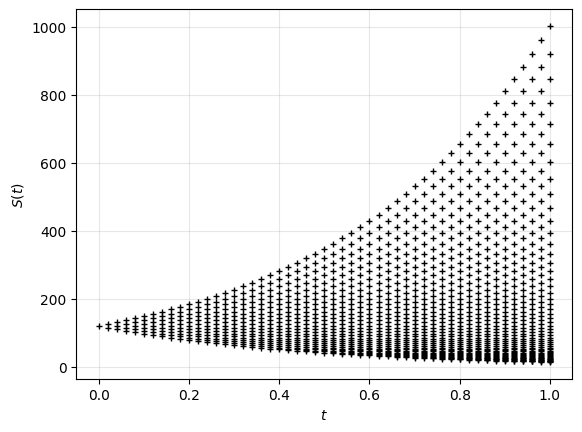

In [11]:
for i in range(M + 1):
    plt.plot(np.repeat(i * delta_t, i + 1), S[:i + 1, i], '+', color='black', markersize=4)
plt.grid(alpha=0.3)
plt.xlabel('$t$')
plt.ylabel('$S(t)$')
plt.show()

# Interpretation: As the time going bigger and biger, we would have more possibilities. Volatility getting bigger and bigger.
# The value of stocks remain strictly positive.

**Task 2.2**: Copy the above code snippet under Task 2.1 and adapt the code so that it visualizes the option price matrix `V` instead of `S`. What do you observe compared to the output of Task 2.1? Interpret your plot using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/1_2_2.png" width="550"><details>
  <summary>Interpretation:</summary> It can clearly be seen that the prices of call options and of the underlying stock are highly correlated in the binomial model. Compared to the stock price matrix $S$, the binomial tree for $V$ becomes even more compressed for low stock prices at the bottom since for these low stock prices it becomes increasingly unlikely that the option finishes in the money.

 </details>
</details>

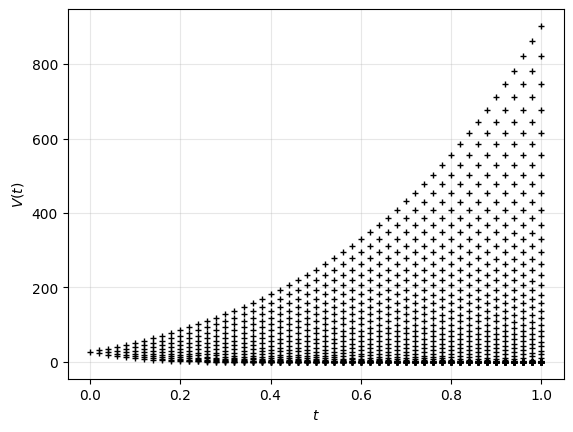

In [13]:
for i in range(M + 1):
    plt.plot(np.repeat(i * delta_t, i + 1), V[:i + 1, i], '+', color='black', markersize=4)
plt.grid(alpha=0.3)
plt.xlabel('$t$')
plt.ylabel('$V(t)$')
plt.show()

# Interpretation: The Values of V(t) are smaller than S(t), because we discount it by multiplying it by 
# np.exp(r * delta_t) [exp^(-r * delta_t)]. The values of V(t) >= 0, because options are limited liability instruments, therefore
# generally it won't go below 0, and all the values below the strike price are zero (call option), therefore, we can see that many 
# values are around zero. 
# S(t) denotes the value of stocks itself and V(t) denotes the value of the portofolios (bonds are included in calculation).

We now want to visualize one specific realization of a stock price path in the binomial model as well as the corresponding realisation of the option price path. Suppose that the empirical probability of an upwards movement in the binomial model is given by $p = 0.5$.

**Task 2.3**: Fill the blank spaces (marked by `...`) in the code snippet below: First, initialize an random number generator `rng` with random seed 24. Then, use the function `rng.binomial` to draw $M$ samples of a Bernoulli distribution with parameter $p = 0.5$ and store these draws in an array `coin_flips`. The code snippet then continues to visualize the simulated stock price path and the simulated option price path that correspond to your randomly drawn coin flips for the up and down movements.

*Useful Python commands*: `np.random.default_rng(...)`

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/1_2_3.png" width="950">
</details>

[0 0 1 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 1 0 1 0 1 0
 0 0 1 0 0 0 1 1 0 1 1 0 0]
50


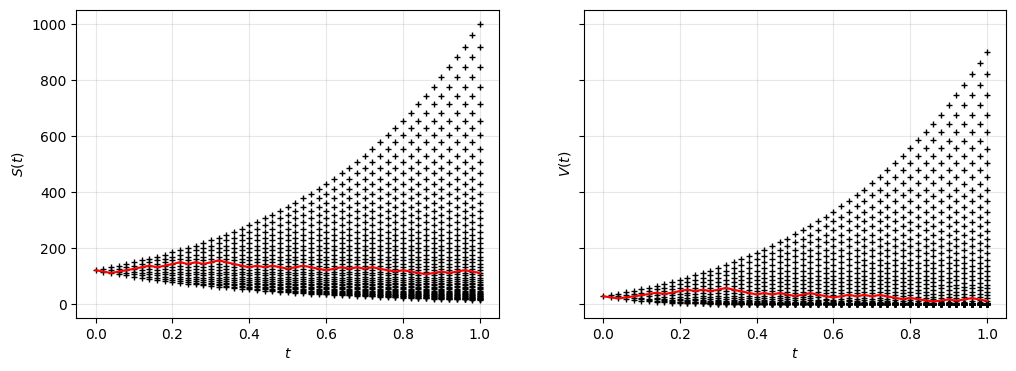

In [14]:
rng = np.random.default_rng(seed=24)
coin_flips = rng.binomial(1, p = 0.5, size = M ) # For the parameters, we need the Bernoulli and we add it up on the next line
binomial_path = coin_flips.cumsum()
binomial_path = np.append(0, binomial_path)

print(coin_flips)
print(len(coin_flips))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i in range(M + 1):
    ax[0].plot(np.repeat(i * delta_t, i + 1), S[:i + 1, i], '+', color='black', markersize=4)
    ax[1].plot(np.repeat(i * delta_t, i + 1), V[:i + 1, i], '+', color='black', markersize=4)
ax[0].grid(alpha=0.3)
ax[1].grid(alpha=0.3)
ax[0].set_xlabel('$t$')
ax[1].set_xlabel('$t$')
ax[0].set_ylabel('$S(t)$')
ax[1].set_ylabel('$V(t)$')
ax[0].plot(np.linspace(0, 1, M + 1), S[binomial_path, np.arange(M + 1)], color='red')
ax[1].plot(np.linspace(0, 1, M + 1), V[binomial_path, np.arange(M + 1)], color='red')
plt.show()

<br><br>

## Step 3: Examining no-arbitrage bounds and the put-call parity

By standard no-arbitrage arguments, the price $V_{\mathrm{call}}(0)$ of a European call option with strike $K$ lies inside the bounds $S(0) - K e^{-rT} \leq V_{\mathrm{call}}(0) \leq S(0)$ in any model. Likewise, the price $V_{\mathrm{put}}(0)$ of a European put option with strike $K$ lies inside the bounds $0 \leq V_{\mathrm{put}}(0) \leq K e^{-rT}$ in any model. We now want to examine how the call and put option prices behave with respect to these bounds when the volatility $\sigma$ of the binomial model is varied.

**Task 3.1**: Define an array `sigmas` that contains 500 equally spaced values of $\sigma$ between 0.01 and 5. Then, define two functions `g_call(S)` and `g_put(S)` that compute the payoff of a call option with strike $K = 100$ and the payoff of a put option with strike $K = 100$, respectively, as a function of $S(T)$.

*Useful Python commands*: `np.linspace`, `np.maximum`

In [15]:
sigmas = np.linspace(0.01, 5, 500)

def g_calls(S):
    return np.maximum(S - 100, 0)


def g_puts(S):
    return np.maximum(100 - S, 0)


v_call = g_calls(104)
print(v_call)

v_puts = g_puts(44)
print(v_puts)

### Uncomment and execute the following lines only if you obtained no result:
# sigmas1 = np.loadtxt('../shared_materials/objects/1_3_1.txt')
# g_call = types.FunctionType(marshal.load(open('../shared_materials/objects/1_3_1a.mar', 'rb')), globals())
g_put = types.FunctionType(marshal.load(open('../shared_materials/objects/1_3_1b.mar', 'rb')), globals())

#values2 = g_call(70)
#print(values2)

#values4 = g_put(34)
#print(values4)


4
56


**Task 3.2**: Define an array `call_prices_CRR` of length 500 and an array `put_prices_CRR` of length 500 and use a for-loop and your function `european_CRR` to fill these with the call and put prices in the binomial model with $M=100$ with the volatility $\sigma$ taking values in the array `sigmas` and all other input variables as before.

In [16]:
call_prices_CRR = np.zeros(500)
put_prices_CRR = np.zeros(500)

for i in range(len(sigmas)):
    call_prices_CRR[i] = (european_call_CRR(g1, S0, T, r, sigmas[i], 100))
    put_prices_CRR[i] = (european_put_CRR(g2, S0, T, r, sigmas[i], 100))
    
print(call_prices_CRR)
print(put_prices_CRR)
                                  

### Uncomment and execute the following line only if you obtained no result:
call_prices_CRR1, put_prices_CRR1 = np.loadtxt('../shared_materials/objects/1_3_2.txt')

print(call_prices_CRR1)

print((np.round(call_prices_CRR, 10) == (np.round(call_prices_CRR1, 10))))


[ 21.98013267  21.98013267  21.98013267  21.98013279  21.98015959
  21.98071217  21.9840889   21.9958584   22.02073893  22.0650802
  22.13393131  22.22743545  22.33684019  22.48629689  22.64070572
  22.83358792  23.03833072  23.24622749  23.4929755   23.75313581
  24.0156893   24.28030457  24.55670974  24.87125325  25.18736889
  25.50485389  25.82353407  26.14325891  26.46389757  26.7853357
  27.13308154  27.49699844  27.86148282  28.22645272  28.59183467
  28.95756255  29.3235766   29.68982263  30.05625125  30.42281737
  30.7894796   31.15619988  31.52294309  31.88967667  32.25637043
  32.63656646  33.03360848  33.43048435  33.82716736  34.22363229
  34.61985527  35.01581365  35.4114859   35.80685151  36.20189088
  36.59658528  36.99091672  37.38486796  37.7784224   38.17156405
  38.56427747  38.95654774  39.34836043  39.73970154  40.13055749
  40.52091509  40.91076152  41.30008427  41.68887116  42.07711032
  42.46479014  42.85189928  43.23842666  43.6243614   44.00969287
  44.3944106

**Task 3.3**: Plot the call prices from the array `call_prices_CRR` against the values of $\sigma$ stored in the array `sigmas`. Use the function `plt.axhline` to draw horizontal lines at the height of the no-arbitrage lower bound $S(0) - K e^{-rT}$ and the upper bound $S(0)$.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/1_3_3.png" width="550">
</details>

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_41/3154247292.py:2: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('sigmas' + ' ' + "$\sigma$")


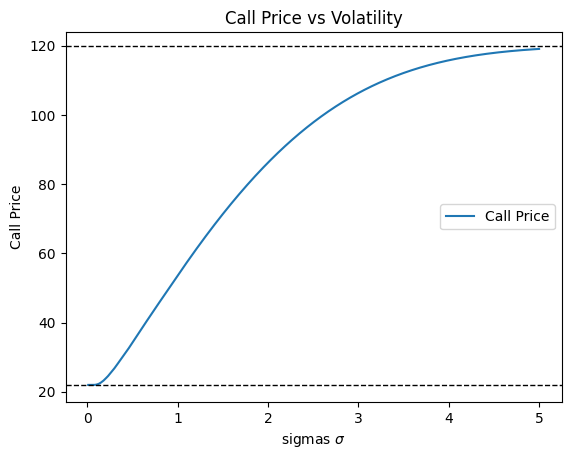

In [17]:
plt.plot(sigmas, call_prices_CRR, label = 'Call Price')
plt.xlabel('sigmas' + ' ' + "$\sigma$")
plt.ylabel('Call Price')
plt.title('Call Price vs Volatility')
plt.axhline(y=S0, color = 'black', linestyle = '--', linewidth = 1)
plt.axhline(y=S0 - K * np.exp(-r * T), color = 'black', linestyle = '--', linewidth = 1)

plt.legend()
plt.show()

**Task 3.4**: Plot the put prices from the array `put_prices_CRR` against the values of $\sigma$ stored in the array `sigmas`. Use the function `plt.axhline` to draw horizontal lines at the height of the no-arbitrage lower bound $0$ and the upper bound $K e^{-rT}$. Interpret your plots from Task 3.3 and Task 3.4 in a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/1_3_4.png" width="550"><details>
  <summary>Interpretation:</summary> Even though call and put prices often behave opposite of each other, e.g. when plotted against the initial stock price $S(0)$ or against the strike price $K$, this is not the case when plotted against volatility $\sigma$. Both call and put prices increase with a higher value of $\sigma$ and decrease with a lower value of $\sigma$, exhausting the whole no-arbitrage ranges given by the dashed lines. The reason for that is that a higher value of $\sigma$ symmetrically increases both the probability of very high and very low stock prices $S(T)$ and hence both the probability of call and of put options to expire in the money with a high payoff, while the downside risk of both options is bounded. 

 </details>
</details>

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_41/3311254511.py:2: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('sigmas' + ' ' + "$\sigma$")


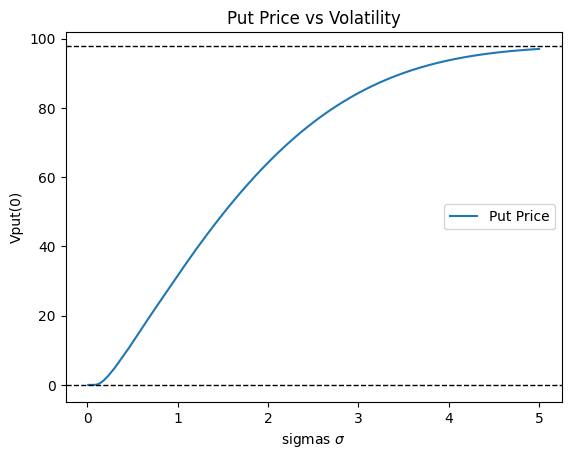

In [18]:
plt.plot(sigmas, put_prices_CRR, label = 'Put Price')
plt.xlabel('sigmas' + ' ' + "$\sigma$")
plt.ylabel('Vput(0)')
plt.title('Put Price vs Volatility')
plt.axhline(y= K * np.exp(-r * T), color = 'black', linestyle = '--', linewidth = 1)
plt.axhline(y= 0, color = 'black', linestyle = '--', linewidth = 1)

plt.legend()
plt.show()

# Interpretation: ...

<br>

The *put-call parity* relationship states that $V_{\mathrm{put}}(t) = K e^{-r(T - t)} - S(0) + V_{\mathrm{call}}(t)$ holds for any $t \in [0, T]$ and in any dividend-free model (with numeraire $B(t) = e^{rt}$).

**Task 3.5**: Verify that the put-call parity holds by plotting the difference of the left-hand side and the right-hand side in the above equation against the values of $\sigma$ stored in the array `sigmas` by using the call and put values stored in the arrays `call_prices_CRR` and `put_prices_CRR`.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/1_3_5.png" width="550">
</details>

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_41/4127936452.py:12: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('sigmas' + ' ' + "$\sigma$")


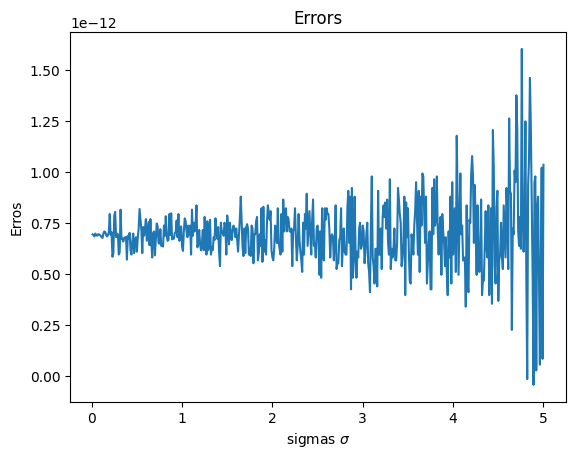

In [19]:
errors = np.zeros(len(sigmas))

print(errors)

for i in range(len(sigmas)):
    errors[i] = (call_prices_CRR[i] - put_prices_CRR[i]) + (K * np.exp(-r * T) - S0)

print(errors)
print(sigmas)

plt.plot(sigmas, errors, label = 'Errors')
plt.xlabel('sigmas' + ' ' + "$\sigma$")
plt.ylabel('Erros')
plt.title('Errors')
#plt.axhline(y= K * np.exp(-r * T), color = 'black', linestyle = '--', linewidth = 1)
#plt.axhline(y= 0, color = 'black', linestyle = '--', linewidth = 1)

plt.show()

<br><br>

## Step 4: Valuation of down-and-out call options in the binomial model

Valuing path-dependent exotic options in the binomial model is not always straightforward because in general, the recombining structure of the tree cannot be used when dealing with path-dependencies. An exception to this are Barrier options like *down-and-out call options* that we will deal with below. A down-and-out call option has the payoff $V(T) = 1_{\{S(t_i) \geq B \text{ for any } i = 0, \dots, M\}} (S(T) - K)^+$ at the terminal time $T$, i.e. it pays out the payoff of a European put option as long as the stock price never fell below a pre-defined barrier $B$ at any time before, in which case the option pays out nothing. The following pseudo code summarizes the computation of down-and-out call options in the binomial model, which is detailed in Section 1.3 of the lecture:

**Input** $r, \sigma, S(0), T, K, B, M$ <br>
**Compute** $\Delta t := T/M$ <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; Set $u, d, q$ according to $(1.4 - 1.7)$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; Set $S_{00} := S(0)$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $S_{ji} := S_{00} u^jd^{i-j}$ for $i = 1, \dots, M$ and $j = 0, \dots, i$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $V_{jM}$ according to $(1.16)$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **for** $i = 1, \dots, M$ and $j = 0, \dots, i$: <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $V_{ji}$ according to $(1.14)$. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $V_{ji} = 0$ if $S_{ji} < B$. <br>
**Output** $V_{00}$

**Task 4.1**: Modify your function `european_CRR` from Task 1.4 and define a new function `down_and_out_call_CRR(S0, K, T, B, r, sigma, M)` that implements the above pseudo code and returns the initial price of a down-and-out call option with barrier $B$ and strike $K$.

In [22]:
def down_and_out_call_CRR(g1, S0, K, T, B, r, sigma, M):
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    for j in range(M+1):
        if S[j, M] >= B:
            V[j, M] = g1(S[j, M])
        else : 
            V[j, M] = 0
    
    #V[:M+1, M] = g1(S[:M+1, M])

    # Backward induction
    for i in range(M, 0, -1):
        for j in range(i):
            if S[j, i-1] >= B:
                 V[j, i-1] = np.exp(-r * delta_t) * (
                     q * V[j+1, i] + (1 - q) * V[j, i]
                 )
            else :
                V[j, i-1] = 0

    return V[0, 0]

K = 50
g1 = lambda S: np.maximum(S - K, 0) 



price = down_and_out_call_CRR(g1, S0=100, K = 50, T=1, B = 50, r=0.05, sigma=0.2, M=50)

print(price)

### Uncomment and execute the following line only if you obtained no result:
down_and_out_call_CRR1 = types.FunctionType(marshal.load(open('../shared_materials/objects/1_4_1.mar', 'rb')), globals())
price = down_and_out_call_CRR1(S0=100, K= 50, T=1, B =50, r=0.05, sigma=0.2, M=50)
print(price)


52.43861030941885
52.43861030941885


Now, we want to visualize the sensitivity of the down-and-out call option prices in the binomial model with respect to the value $B$ of the barrier. 

**Task 4.2**: Define an array `B_values` that contains 100 equally spaced values of $B$ between 50 and 150. Then, use a for-loop and your function `down_and_out_call_CRR` from Task 4.1 to compute the barrier option values in the binomial model with $M = 500$ for $B$ taking values in the array `B_values` and all other input variables as before. Store these option prices in an array `barrier_prices_CRR`.

*Useful Python commands*: `np.linspace`

In [23]:
B_values = np.linspace(50, 150, 100)

print(len(B_values))
K=100
g1 = lambda S: np.maximum(S - K, 0) 

barrier_prices_CRR = np.zeros(len(B_values))
# print(barrier_prices_CRR)
# print(len(barrier_prices_CRR))

for i in range(len(B_values)):
    barrier_prices_CRR[i] = down_and_out_call_CRR(g1, S0=120, K = 100, T = 1, B = B_values[i], r = 0.02, sigma=0.3, M = 500)

print(B_values)
print(barrier_prices_CRR)
# print(len(B_values))
# print(len(barrier_prices_CRR))


### Uncomment and execute the following line only if you obtained no result:
B_values1, barrier_prices_CRR1 = np.loadtxt('../shared_materials/objects/1_4_2.txt')
print(B_values1, barrier_prices_CRR1)

np.array_equal(B_values1, B_values)
np.array_equal(barrier_prices_CRR1, barrier_prices_CRR)

100
[ 50.          51.01010101  52.02020202  53.03030303  54.04040404
  55.05050505  56.06060606  57.07070707  58.08080808  59.09090909
  60.1010101   61.11111111  62.12121212  63.13131313  64.14141414
  65.15151515  66.16161616  67.17171717  68.18181818  69.19191919
  70.2020202   71.21212121  72.22222222  73.23232323  74.24242424
  75.25252525  76.26262626  77.27272727  78.28282828  79.29292929
  80.3030303   81.31313131  82.32323232  83.33333333  84.34343434
  85.35353535  86.36363636  87.37373737  88.38383838  89.39393939
  90.4040404   91.41414141  92.42424242  93.43434343  94.44444444
  95.45454545  96.46464646  97.47474747  98.48484848  99.49494949
 100.50505051 101.51515152 102.52525253 103.53535354 104.54545455
 105.55555556 106.56565657 107.57575758 108.58585859 109.5959596
 110.60606061 111.61616162 112.62626263 113.63636364 114.64646465
 115.65656566 116.66666667 117.67676768 118.68686869 119.6969697
 120.70707071 121.71717172 122.72727273 123.73737374 124.74747475
 125.757

True

**Task 4.3**: Plot the down-and-out call option prices stored in the array `barrier_prices_CRR` against the values of $B$ stored in the array `B_values`. Interpret your result using a comment. What does the barrier option price converge to when the barrier $B$ becomes very small or very large? What would happen to the plot if you let $M$ go to infinity?

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/1_4_3.png" width="550"><details>
  <summary>Interpretation:</summary> As expected, one can see that the down-and-out call option prices monotonically decreases with the barrier $B$ because a larger barrier means a larger probability of getting knocked out. For barriers larger than the value $S(0) = 120$, the option price is identically zero because the option gets knocked out already at time $0$. If the barrier $B$ becomes very small, the down-and-out-call option price flattens out at the value of a regular European call option because getting knocked out becomes a more and more improbable event. The obscure spikes in the curve originate from the discrete nature of the binomial model. When $M \to \infty$, these spikes become tinier and disappear completely in the limit with the whole curve converging to the smooth curve of a down-and-out call option in the Black&ndash;Scholes model.

 </details>
</details>

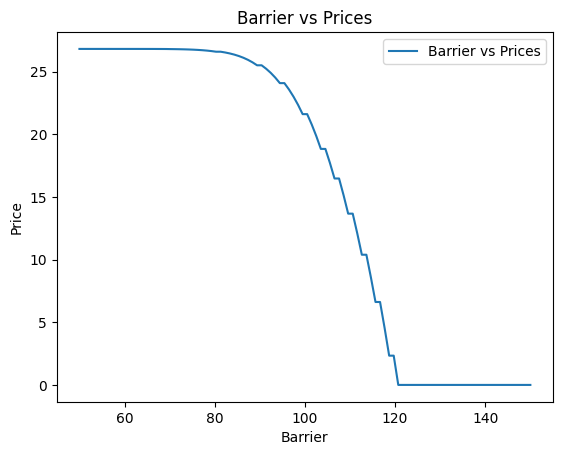

In [26]:
plt.plot(B_values, barrier_prices_CRR, label = 'Barrier vs Prices')
plt.xlabel('Barrier')
plt.ylabel('Price')
plt.title('Barrier vs Prices')

plt.legend()
plt.show()

# Interpretation: The price of the option getting smaller and smaller as the value of the barrier getting bigger and bigger.
#                 When the value of the barrier approximately exceed 120, the value of options is 0.

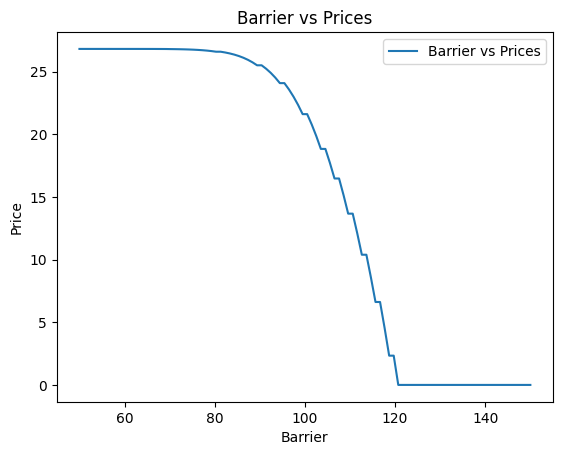

In [27]:
plt.plot(B_values, barrier_prices_CRR1, label = 'Barrier vs Prices')
plt.xlabel('Barrier')
plt.ylabel('Price')
plt.title('Barrier vs Prices')

plt.legend()
plt.show()